# Experiment 7: Convergence Study of a Genetic Algorithm
**Aim:** To study the convergence of a Genetic Algorithm by observing changes in fitness values over multiple generations using Python.

**Problem:** Minimise the 5-D Rastrigin function  f(x) = 10n + Σ [xᵢ² − 10cos(2πxᵢ)],  xᵢ ∈ [−5.12, 5.12]  (global minimum 0 at x = 0).

**GA:** real-coded · tournament selection · arithmetic crossover · Gaussian mutation · elitism.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

DIM, LOW, HIGH = 5, -5.12, 5.12
POP_SIZE, N_GEN = 60, 100

def rastrigin(x):
    x = np.asarray(x)
    return 10 * len(x) + np.sum(x ** 2 - 10 * np.cos(2 * np.pi * x))

def run_ga(pm=0.1, pc=0.9, sigma=0.3, tsize=3, elite=2, seed=None):
    rng = random.Random(seed); nrng = np.random.RandomState(seed)
    pop = nrng.uniform(LOW, HIGH, (POP_SIZE, DIM))
    best, mean, worst = [], [], []
    for g in range(N_GEN):
        fit = np.array([rastrigin(i) for i in pop])
        best.append(fit.min()); mean.append(fit.mean()); worst.append(fit.max())
        order = np.argsort(fit)
        new = [pop[i].copy() for i in order[:elite]]
        def tour():
            c = rng.sample(range(POP_SIZE), tsize)
            return pop[min(c, key=lambda i: fit[i])]
        while len(new) < POP_SIZE:
            a, b = tour().copy(), tour().copy()
            if rng.random() < pc:
                al = rng.random()
                a, b = al * a + (1 - al) * b, (1 - al) * a + al * b
            for c in (a, b):
                mask = nrng.rand(DIM) < pm
                c[mask] += nrng.normal(0, sigma, mask.sum())
                np.clip(c, LOW, HIGH, out=c)
                new.append(c)
        pop = np.array(new[:POP_SIZE])
    return np.array(best), np.array(mean), np.array(worst)

## 1. Best / average / worst fitness in a single run

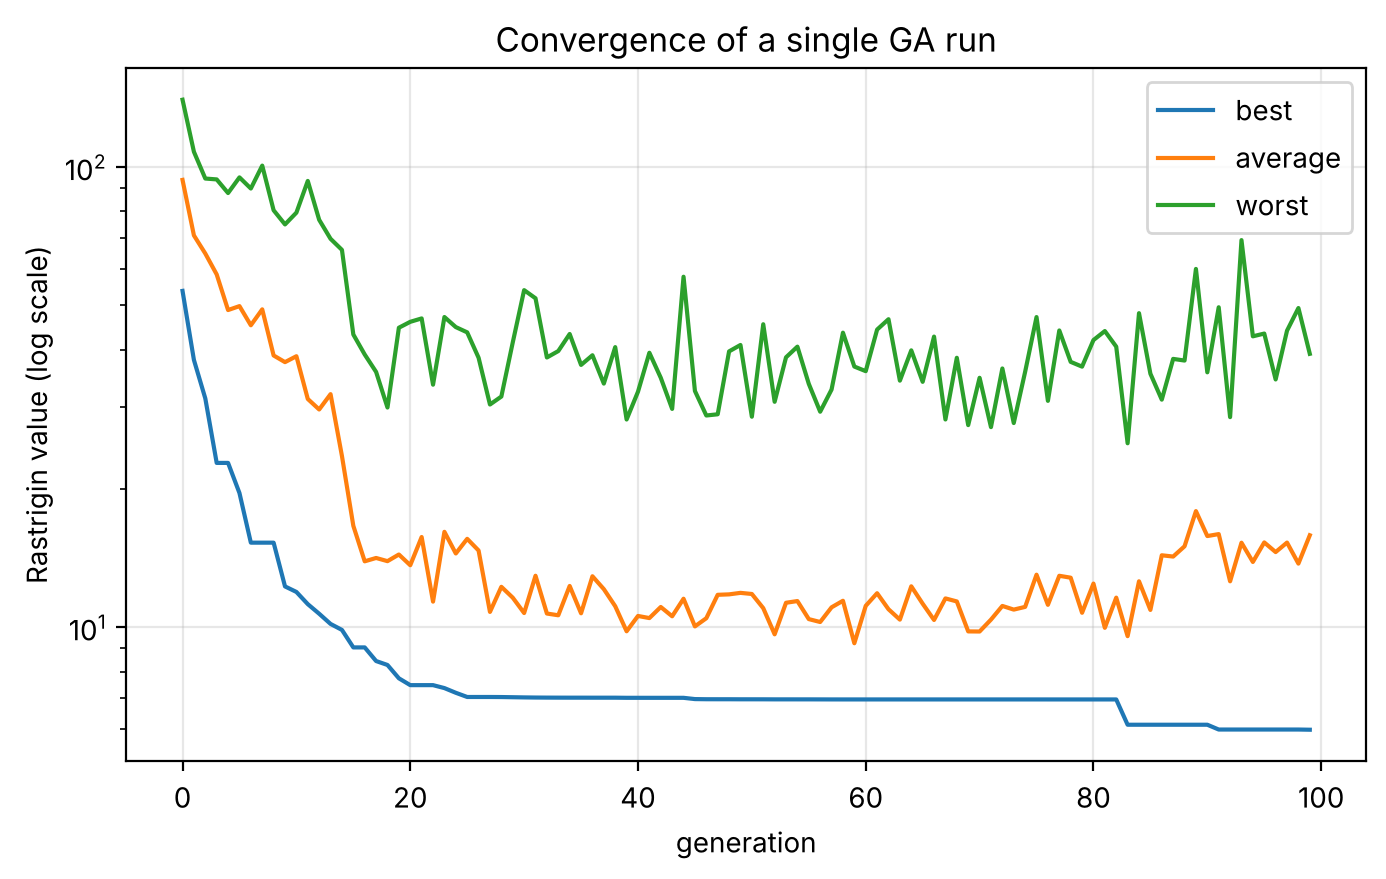

Final best fitness: 5.98616


In [2]:
best, mean, worst = run_ga(seed=1)
plt.figure(figsize=(8, 4.5))
plt.plot(best, label="best"); plt.plot(mean, label="average"); plt.plot(worst, label="worst")
plt.yscale("log"); plt.xlabel("generation"); plt.ylabel("Rastrigin value (log scale)")
plt.title("Convergence of a single GA run"); plt.legend(); plt.grid(alpha=0.3); plt.show()
print("Final best fitness:", round(best[-1], 5))

## 2. Reliability: 15 independent runs (mean ± std of best fitness)

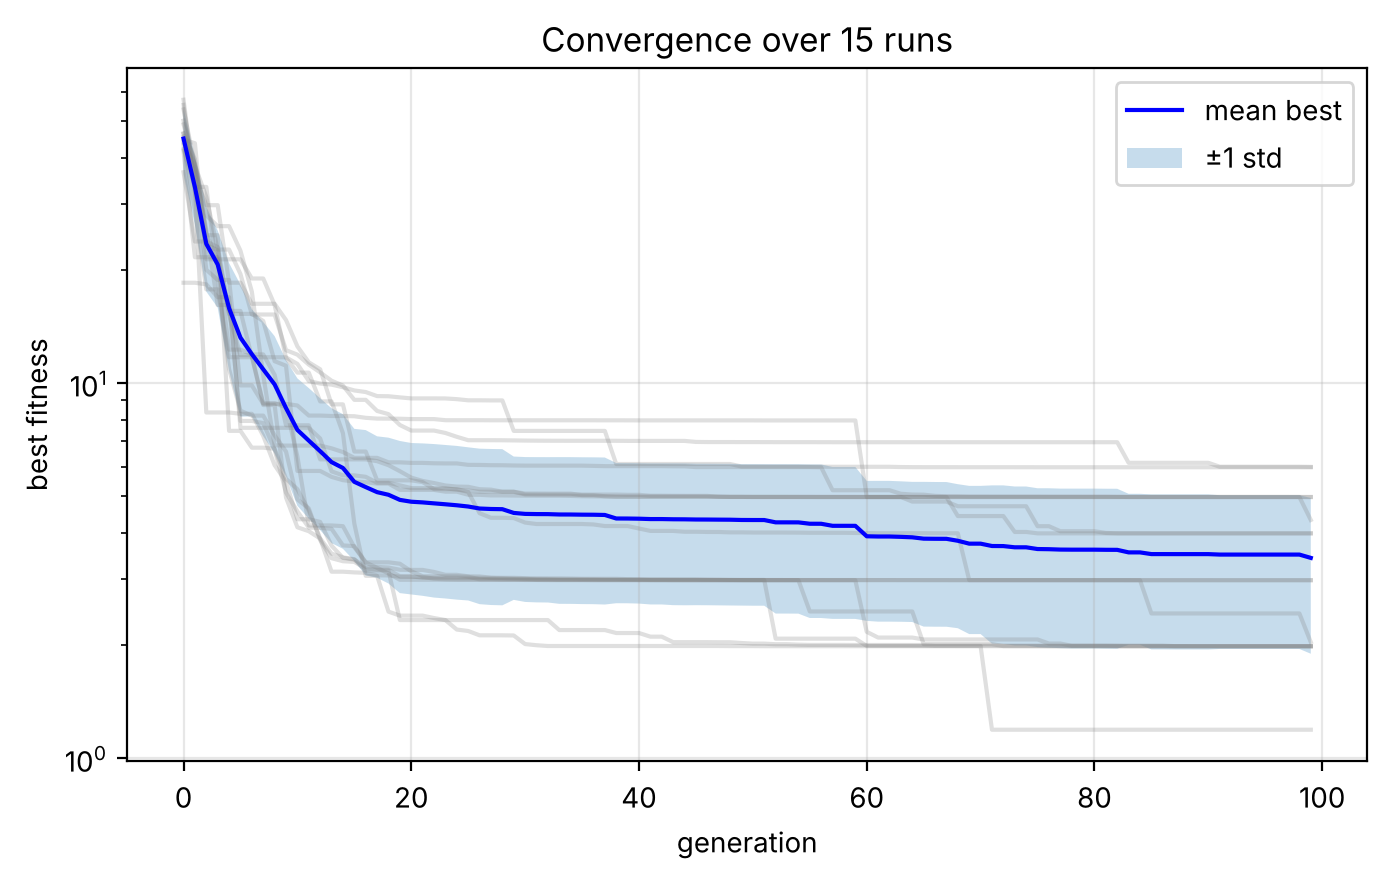

Final best (mean ± std): 3.4235 ± 1.5230


In [3]:
runs = np.array([run_ga(seed=s)[0] for s in range(15)])
m, s = runs.mean(axis=0), runs.std(axis=0)
plt.figure(figsize=(8, 4.5))
for r in runs: plt.plot(r, color="gray", alpha=0.25)
plt.plot(m, color="blue", label="mean best")
plt.fill_between(range(N_GEN), np.maximum(m - s, 1e-6), m + s, alpha=0.25, label="±1 std")
plt.yscale("log"); plt.xlabel("generation"); plt.ylabel("best fitness")
plt.title("Convergence over 15 runs"); plt.legend(); plt.grid(alpha=0.3); plt.show()
print(f"Final best (mean ± std): {m[-1]:.4f} ± {s[-1]:.4f}")

## 3. Effect of mutation rate on convergence

Pm = 0.01  -> final mean best = 4.2046


Pm = 0.1   -> final mean best = 3.5380


Pm = 0.3   -> final mean best = 2.8756


Pm = 0.6   -> final mean best = 1.9686


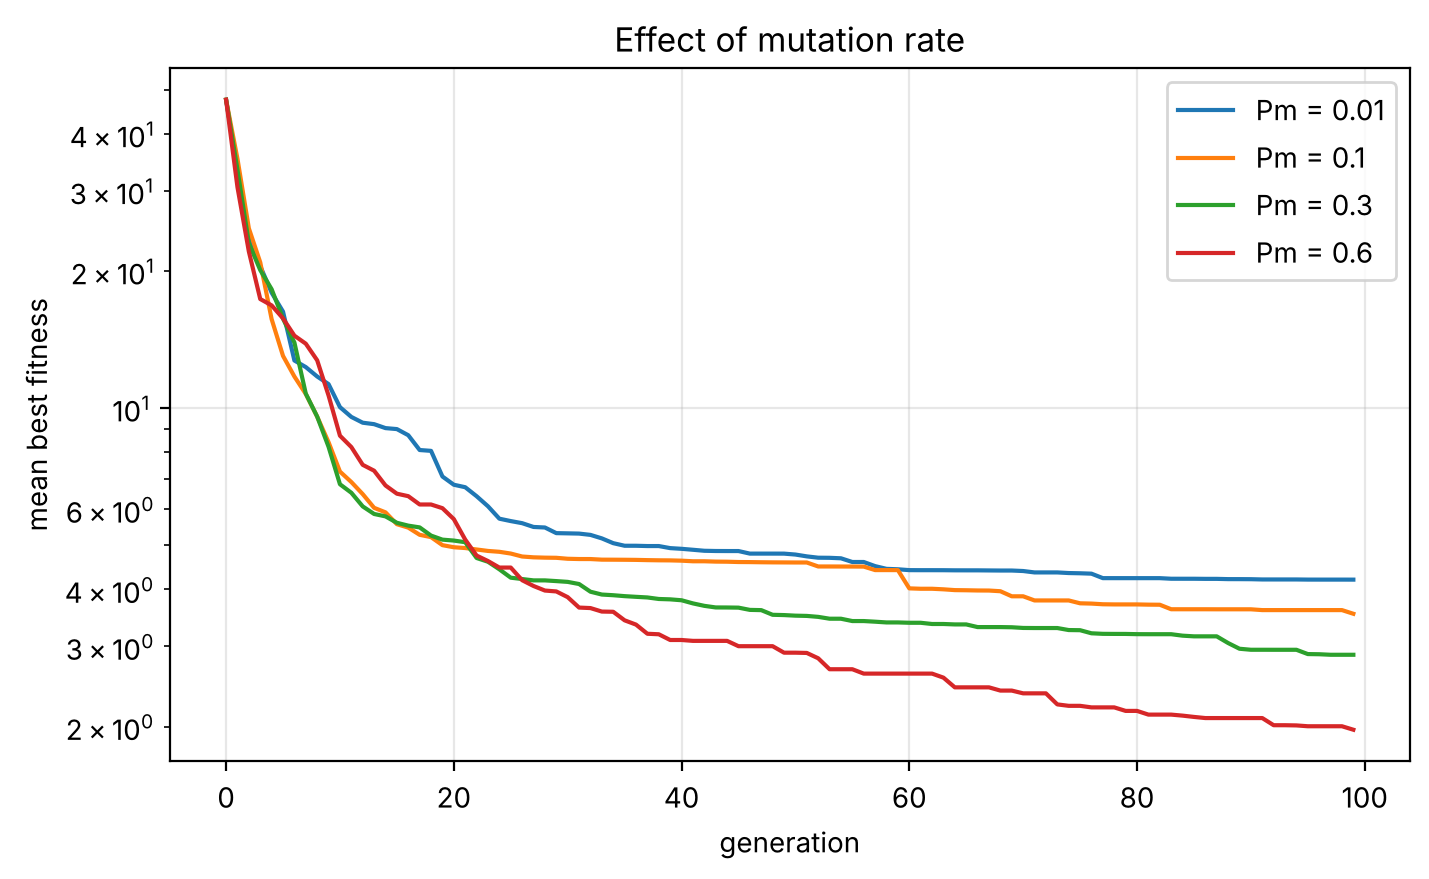

In [4]:
plt.figure(figsize=(8, 4.5))
for pm in [0.01, 0.1, 0.3, 0.6]:
    r = np.array([run_ga(pm=pm, seed=s)[0] for s in range(10)]).mean(axis=0)
    plt.plot(r, label=f"Pm = {pm}")
    print(f"Pm = {pm:<5} -> final mean best = {r[-1]:.4f}")
plt.yscale("log"); plt.xlabel("generation"); plt.ylabel("mean best fitness")
plt.title("Effect of mutation rate"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 4. Generations needed to reach a target (f < 1.0)

In [5]:
gens = []
for s in range(15):
    b = run_ga(seed=s)[0]
    hit = np.where(b < 1.0)[0]
    gens.append(int(hit[0]) if len(hit) else None)
print("Generation first below 1.0 per run:", gens)
ok = [g for g in gens if g is not None]
print(f"Success: {len(ok)}/15, mean generations = {np.mean(ok):.1f}" if ok else "No run reached the target")

Generation first below 1.0 per run: [None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]
No run reached the target


## Observations & Conclusion
- Best fitness drops steeply in the first generations and then flattens; the gap between best and average narrows as the population converges.
- Too small a mutation rate converges fast but can stall in a local minimum; too large a rate keeps the population noisy and slows final refinement.
- Multiple independent runs give a more reliable picture of convergence than a single run.